# Lab 4-1 — Visualization notebook

**This notebook is a working tool, not a deliverable — you do NOT submit it.**

It contains no logic of its own: it imports your finished functions from `../src/lab04_1.py`
and plots their output. If a cell below fails, the bug is in your `.py`, not in the plot.

Your job: complete the three plot cells, then **export each figure and paste it into
`report.pdf`** (right-click → Save image as…, or `plt.savefig('fig1.png', dpi=150)`).
Figures 1–3 are required by the report template.

In [1]:
import sys
sys.path.insert(0, '../src')
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import lab04_1

X, y = lab04_1.load_data('../data/press_qc.csv')
X_train, X_val, y_train, y_val = lab04_1.train_val_split(X, y)
results = lab04_1.run_experiment(X, y)
results

{'0.01': {'final_train_loss': 0.6065,
  'max_train_loss': 0.6853,
  'final_val_loss': 0.6049,
  'final_val_accuracy': 0.7063,
  'best_val_accuracy': 0.7063},
 '1.0': {'final_train_loss': 0.2822,
  'max_train_loss': 0.6247,
  'final_val_loss': 0.3608,
  'final_val_accuracy': 0.8812,
  'best_val_accuracy': 0.8938},
 '100.0': {'final_train_loss': 8.203,
  'max_train_loss': 19.4281,
  'final_val_loss': 8.1166,
  'final_val_accuracy': 0.7063,
  'best_val_accuracy': 0.7063}}

## Plot 1 — The data, in the space the network sees

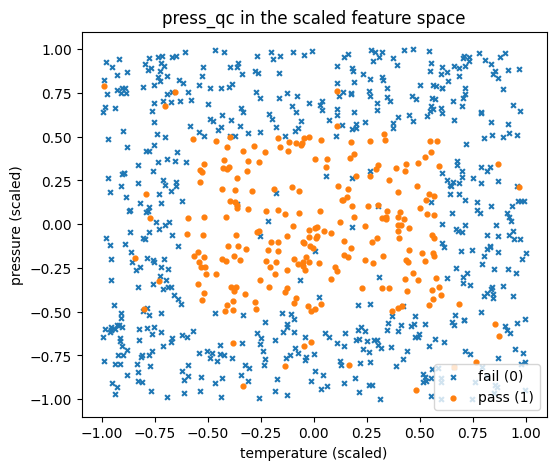

In [2]:
fig, ax = plt.subplots(figsize=(6, 5))
m = y.ravel() == 1
ax.scatter(X[~m, 0], X[~m, 1], s=12, marker='x', label='fail (0)')
ax.scatter(X[m, 0], X[m, 1], s=12, marker='o', label='pass (1)')
ax.set_xlabel('temperature (scaled)')
ax.set_ylabel('pressure (scaled)')
ax.set_title('press_qc in the scaled feature space')
ax.legend()
plt.savefig('fig1.png', dpi=150, bbox_inches='tight')
plt.show()

## Plot 2 — Loss curves for three learning rates

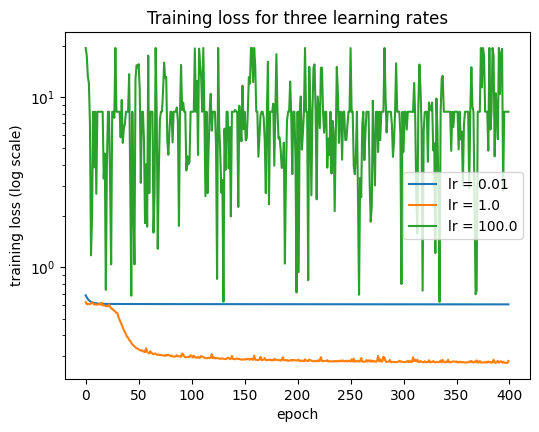

In [3]:
fig, ax = plt.subplots(figsize=(6, 4.5))
for lr in lab04_1.LEARNING_RATES:
    history = lab04_1.train(X_train, y_train, X_val, y_val, lr=lr)[1]
    ax.plot(history['train_loss'], label=f'lr = {lr}')
ax.set_yscale('log')
ax.set_xlabel('epoch')
ax.set_ylabel('training loss (log scale)')
ax.set_title('Training loss for three learning rates')
ax.legend()
plt.savefig('fig2.png', dpi=150, bbox_inches='tight')
plt.show()

## Plot 3 — What the trained network decided

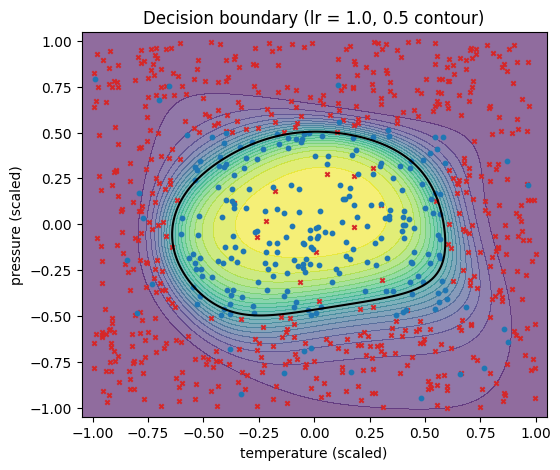

In [4]:
params = lab04_1.train(X_train, y_train, X_val, y_val, lr=1.0)[0]

g = np.linspace(-1.05, 1.05, 200)
gx, gy = np.meshgrid(g, g)
prob = lab04_1.forward(np.column_stack([gx.ravel(), gy.ravel()]), params)['a2'].reshape(gx.shape)

fig, ax = plt.subplots(figsize=(6, 5))
ax.contourf(gx, gy, prob, levels=20, alpha=0.6)
ax.contour(gx, gy, prob, levels=[0.5], colors='k')
m = y.ravel() == 1
ax.scatter(X[~m, 0], X[~m, 1], s=10, marker='x', c='tab:red')
ax.scatter(X[m, 0], X[m, 1], s=10, marker='o', c='tab:blue')
ax.set_xlabel('temperature (scaled)')
ax.set_ylabel('pressure (scaled)')
ax.set_title('Decision boundary (lr = 1.0, 0.5 contour)')
plt.savefig('fig3.png', dpi=150, bbox_inches='tight')
plt.show()